# An ion and its solvent: a probe field for a cation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/15_an_ion_and_its_solvent.ipynb)

An electrolyte solvent and an ionophore have one job: to hold a cation. The energy that a cation
gains when it sits in an ether is a property of the ether, and of where its oxygens are. This
notebook uses 1,050 saturated ethers, each with the binding energy of a lithium, a sodium and a
magnesium ion computed by density functional theory (wB97X-D3/def2-TZVP), and each in the
conformation of its relaxed lithium complex.

The program has a special field for this case: an **ion probe**. A probe field is the energy that
a small test particle would have at every point around the molecule. For an ion probe the test
particle is a cation of a given size and charge. Its deepest point is where the field says the
ion would sit. The notebook asks four questions.

1. Does the probe put the ion where the relaxation put it? This needs no model at all.
2. How well do the fields and the probe predict the binding energy, against counts read from the
   formula?
3. What do the fields read beyond **how many oxygens touch the ion**? This reference is new in
   this notebook.
4. Can anything predict the difference between lithium and sodium, the selectivity?

The data are in `examples/ether/` (MLElectrolytes, Wang et al., Chem. Commun. 56 (2020) 8920).
The long fits are read from the stored results of `benchmarks/run_ether.py`.

Running time: about two minutes.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The series

`load` in the benchmark script reads the structures and the properties. Every record holds the
ether in the conformation of its lithium complex, with the ion removed and its position kept in
the property `ion_xyz`. So the molecule is in the shape that the energy belongs to. The sodium and
magnesium energies were computed on their own complexes, but only the lithium geometries are
distributed: a sodium model built here uses a lithium-shaped conformer.

In [2]:
import json
import os
import sys

os.environ["CMF_KERNEL_CACHE"] = "0"
sys.path.insert(0, "benchmarks")

import matplotlib.pyplot as plt
import numpy as np
from rdkit import RDLogger

RDLogger.DisableLog("rdApp.*")
import run_ether as E                     # the data, the probe, the folds and the fits of item EC7

mols, names, rows = E.load()
o_count = np.array([float(r["o_count"]) for r in rows])
print("%d ethers, %d to %d oxygens, %d to %d heavy atoms" % (
    len(mols), o_count.min(), o_count.max(), min(m.GetNumHeavyAtoms() for m in mols), max(m.GetNumHeavyAtoms() for m in mols)))
for ion in E.ION_ORDER:
    probe, prop, label = E.IONS[ion]
    y = E.target(rows, prop)
    ok = np.isfinite(y)
    print("%-5s %4d energies, mean %6.2f eV, standard deviation %.2f; correlation with the oxygen count %+.2f" % (
        label, ok.sum(), y[ok].mean(), y[ok].std(), np.corrcoef(o_count[ok], y[ok])[0, 1]))

1050 ethers, 2 to 6 oxygens, 5 to 28 heavy atoms
Li+   1048 energies, mean  -3.84 eV, standard deviation 0.58; correlation with the oxygen count -0.62
Na+    980 energies, mean  -2.78 eV, standard deviation 0.57; correlation with the oxygen count -0.60
Mg2+   982 energies, mean -11.68 eV, standard deviation 1.58; correlation with the oxygen count -0.74


The oxygen count alone correlates with every binding energy: more oxygens can wrap the ion more
tightly. It is the first reference any model here has to beat. The magnesium ion, with a charge of
+2, binds about three times as strongly as the monovalent ions.

## Where does the probe put the ion?

The lithium probe field of a molecule is a sum of Gaussian functions that approximates the energy
of a lithium ion at every point. Its deepest point is a prediction of the ion's position, and the
data carry the position that the DFT relaxation gave. This test needs no regression of any kind.
The cell below finds the deepest point for every twentieth molecule on a grid of 0.4 Å, and
compares it with two references that need no field: the centroid of the oxygens and the centroid
of the heavy atoms.

In [3]:
sample = list(range(0, len(mols), 20))
d_probe, d_oxygen, d_heavy = [], [], []
for i in sample:
    ion = E.ion_position(rows[i])
    point, depth = E.deepest_point(mols[i], names[i], "lithium")
    pos = mols[i].GetConformer().GetPositions()
    oxy = [a.GetIdx() for a in mols[i].GetAtoms() if a.GetSymbol() == "O"]
    heavy = [a.GetIdx() for a in mols[i].GetAtoms() if a.GetSymbol() != "H"]
    d_probe.append(np.linalg.norm(point - ion))
    d_oxygen.append(np.linalg.norm(pos[oxy].mean(axis=0) - ion))
    d_heavy.append(np.linalg.norm(pos[heavy].mean(axis=0) - ion))
print("%d molecules; distance from the relaxed ion, mean and share within 1.0 A:" % len(sample))
for label, d in (("deepest point of the probe field", d_probe), ("centroid of the oxygens", d_oxygen),
                 ("centroid of the heavy atoms", d_heavy)):
    d = np.asarray(d)
    print("   %-34s %.2f A   %3.0f %%" % (label, d.mean(), 100 * np.mean(d <= 1.0)))

stored = json.load(open(os.path.join(E.RESULTS, "probe.json")))
print()
print("stored, all %d molecules:" % stored["n"])
for key, label in (("probe_minimum", "deepest point of the probe field"), ("oxygen_centroid", "centroid of the oxygens"),
                   ("heavy_atom_centroid", "centroid of the heavy atoms")):
    s = stored[key]
    print("   %-34s %.2f +/- %.2f A   %3.0f %%" % (label, s["mean"], s["sd"], 100 * s["within_1A"]))

53 molecules; distance from the relaxed ion, mean and share within 1.0 A:
   deepest point of the probe field   0.36 A    96 %
   centroid of the oxygens            0.70 A    89 %
   centroid of the heavy atoms        0.72 A    81 %

stored, all 1050 molecules:
   deepest point of the probe field   0.36 +/- 0.55 A    97 %
   centroid of the oxygens            0.65 +/- 0.74 A    86 %
   centroid of the heavy atoms        0.67 +/- 0.80 A    82 %


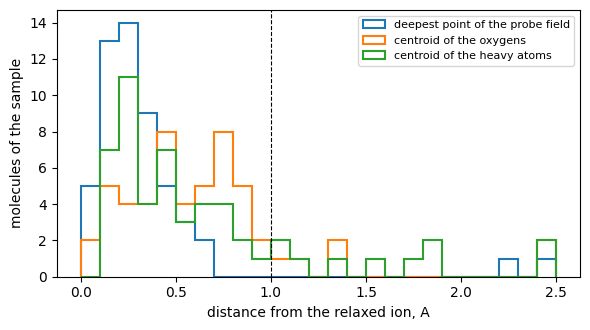

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.4))
bins = np.linspace(0, 2.5, 26)
for d, label in ((d_probe, "deepest point of the probe field"), (d_oxygen, "centroid of the oxygens"),
                 (d_heavy, "centroid of the heavy atoms")):
    ax.hist(np.clip(d, 0, 2.5), bins=bins, histtype="step", lw=1.5, label=label)
ax.axvline(1.0, color="black", ls="--", lw=0.8)
ax.set_xlabel("distance from the relaxed ion, A")
ax.set_ylabel("molecules of the sample")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

On the 53 molecules of the sample, the deepest point of the probe field is 0.36 Å from the relaxed
ion on average, and within 1.0 Å in 96 % of them. The centroid of the oxygens is 0.70 Å away (89 %
within 1.0 Å), and the centroid of the heavy atoms 0.72 Å (81 %). The stored run over all 1,050
complexes gives the same picture: 0.36 against 0.65 and 0.67 Å. So the probe field puts the ion
where the relaxation put it about twice as closely as the obvious geometric guess, with no fitted
number at all.

## The binding energy: fields, probe and counts

`run_ether.py --stage bind` fits six models to each ion with nested cross-validation: five outer
folds, and the ridge and the field width chosen on ten inner folds. Two fold designs: molecules at
random, and one oxygen count held out at a time, which asks for a chain length that the model has
not seen. The models are:

- **counts**: the oxygen count, the carbon-to-oxygen ratio and the number of heavy atoms, with a
  linear kernel;
- **counts+homo**: the same with the energy of the molecule's highest occupied orbital;
- **electrostatic**: the electrostatic field alone;
- **fields**: the five ordinary fields;
- **probe**: the matching ion probe field alone;
- **fields+probe**: the sum of the two kernels.

There is no frame: a glyme has no scaffold to superimpose, so every field enters through the
alignment-free kernel of the second notebook. The table reads the stored result.

In [5]:
bind = json.load(open(os.path.join(E.RESULTS, "bind.json")))
for ion in E.ION_ORDER:
    rec = bind["ions"][ion]
    print("%s: %d molecules; predicting the mean costs %.3f eV" % (E.IONS[ion][2], rec["n"], rec["mae_of_the_mean"]))
    print("   %-14s %18s %26s" % ("model", "random folds", "one oxygen count held out"))
    for m in bind["models"]:
        a = rec["designs"]["random"]["models"][m]
        b = rec["designs"]["one oxygen count held out"]["models"][m]
        print("   %-14s %9.3f (R2 %+.2f) %15.3f (R2 %+.2f)" % (m, a["mae_mean"], a["r2_pooled"], b["mae_mean"], b["r2_pooled"]))
    print()

Li+: 1048 molecules; predicting the mean costs 0.454 eV
   model                random folds  one oxygen count held out
   counts             0.296 (R2 +0.43)           0.284 (R2 +0.42)
   counts+homo        0.254 (R2 +0.55)           0.264 (R2 +0.52)
   electrostatic      0.209 (R2 +0.77)           0.256 (R2 +0.69)
   fields             0.124 (R2 +0.89)           0.186 (R2 +0.86)
   probe              0.140 (R2 +0.88)           0.177 (R2 +0.86)
   fields+probe       0.117 (R2 +0.91)           0.129 (R2 +0.90)

Na+: 980 molecules; predicting the mean costs 0.449 eV
   model                random folds  one oxygen count held out
   counts             0.279 (R2 +0.44)           0.291 (R2 +0.43)
   counts+homo        0.246 (R2 +0.51)           0.254 (R2 +0.50)
   electrostatic      0.248 (R2 +0.57)           0.277 (R2 +0.53)
   fields             0.181 (R2 +0.69)           0.248 (R2 +0.66)
   probe              0.193 (R2 +0.66)           0.243 (R2 +0.59)
   fields+probe       0.171 (R2 +0

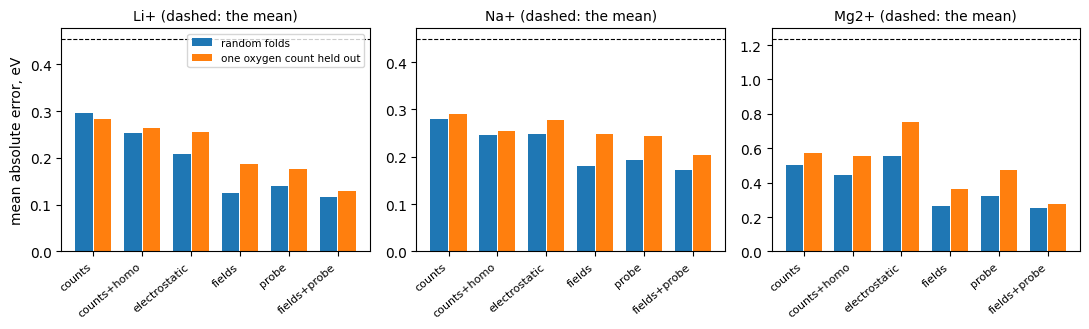

In [6]:
fig, axes = plt.subplots(1, len(E.ION_ORDER), figsize=(11, 3.4))
for ax, ion in zip(axes, E.ION_ORDER):
    rec = bind["ions"][ion]
    models_b = list(bind["models"])
    x = np.arange(len(models_b))
    for j, design in enumerate(("random", "one oxygen count held out")):
        ax.bar(x + (j - 0.5) * 0.38, [rec["designs"][design]["models"][m]["mae_mean"] for m in models_b], 0.36,
               label="random folds" if design == "random" else design)
    ax.axhline(rec["mae_of_the_mean"], color="black", ls="--", lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(models_b, rotation=40, ha="right", fontsize=8)
    ax.set_title("%s (dashed: the mean)" % E.IONS[ion][2], fontsize=10)
axes[0].set_ylabel("mean absolute error, eV")
axes[0].legend(fontsize=7.5)
plt.tight_layout()
plt.show()

On lithium with random folds the fields reach 0.124 eV and the probe alone 0.140 eV, against 0.296
eV for the counts read from the formula and 0.454 eV for the mean. The probe is better than the
electrostatic field alone (0.209 eV), although it is built from the same charges: it samples the
potential where an ion would sit, at its contact distance from the molecule, and not over all
space. The fields and the probe together are best for every ion (0.117, 0.171 and 0.254 eV), and
they keep most of that when a whole oxygen count is held out (0.129, 0.204 and 0.279 eV).

## What the fields read beyond the oxygens that touch the ion

The counts are read off the formula. A stronger reference reads the complex itself. The
**contacts** are the number of oxygens within 2.5 Å of the ion (the gap between the first shell of
oxygens, at 1.8 to 2.4 Å, and the rest), their mean distance, and the sum of 1/d over the oxygens
within 3.5 Å. They are added to the three counts. The cell computes them for every molecule at
the relaxed ion position, and shows how the binding energy of lithium falls with the number of
contacts.

contacts per complex: {1: 21, 2: 47, 3: 124, 4: 467, 5: 362, 6: 29}
correlation with the lithium binding energy: contacts -0.79, oxygen count -0.62


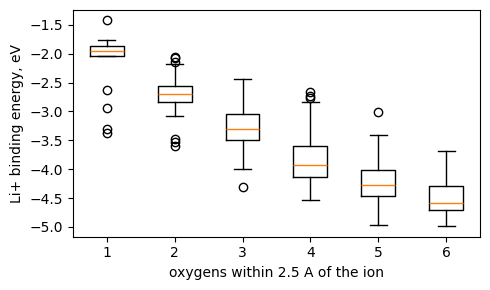

In [7]:
contacts = np.array([E.contact_features(m, E.ion_position(r)) for m, r in zip(mols, rows)])
y_li = E.target(rows, "li_ebind")
ok = np.isfinite(y_li)
print("contacts per complex:", {int(k): int(v) for k, v in zip(*np.unique(contacts[:, 0], return_counts=True))})
print("correlation with the lithium binding energy: contacts %+.2f, oxygen count %+.2f" % (
    np.corrcoef(contacts[ok, 0], y_li[ok])[0, 1], np.corrcoef(o_count[ok], y_li[ok])[0, 1]))

fig, ax = plt.subplots(figsize=(5.0, 3.0))
levels = sorted(set(contacts[ok, 0].astype(int)))
ax.boxplot([y_li[ok][contacts[ok, 0] == k] for k in levels])
ax.set_xticks(range(1, len(levels) + 1))
ax.set_xticklabels([str(k) for k in levels])
ax.set_xlabel("oxygens within 2.5 A of the ion")
ax.set_ylabel("Li+ binding energy, eV")
plt.tight_layout()
plt.show()

A linear fit of the lithium energy, run here with the folds of the benchmark (the printed name after
the label is the kernel the benchmark calls "counts": a linear kernel on standardised columns):

In [8]:
counts, _ = E.count_features(mols, rows)
ok_i = np.where(ok)[0]
folds = E.random_folds(len(ok_i))
for label, X in (("three counts: ", counts), ("with contacts:", np.column_stack([counts, contacts]))):
    rec = E.nested("counts", {}, (), y_li[ok_i], folds, X[ok_i], label=label + " ")

    three counts:  counts         MAE 0.296 +/- 0.012 eV, R2 +0.431  (4 s)


    with contacts: counts         MAE 0.208 +/- 0.017 eV, R2 +0.771  (4 s)


The contacts read the relaxed position of the ion, which no field model sees: the fields are
computed on the molecule alone. So the comparison is put two ways. `run_ether.py --stage contacts`
fits the contacts at the relaxed ion, and the same contacts at the deepest point of the probe field,
which uses nothing but the molecule. Both are fitted with a linear kernel and with a Gaussian kernel
whose width is chosen inside each fold, beside the counts with a Gaussian kernel. The references
then get the nonlinear fit that the fields have. The fields, the probe and the counts are the
stored models of the previous table, on the same folds, so every difference is paired.

In [9]:
cont = json.load(open(os.path.join(E.RESULTS, "contacts.json")))
print("the number of contacts is the same at the relaxed ion and at the probe minimum for %.0f %% of the molecules" % (
    100 * cont["agreement"]["same_count"]))
for ion in E.ION_ORDER:
    for design in ("random", "one oxygen count held out"):
        d = cont["ions"][ion]["designs"][design]
        print()
        print("%s, %s: MAE in eV" % (E.IONS[ion][2], "random folds" if design == "random" else design))
        for b in ("counts", "fields", "probe", "fields+probe"):
            print("   %-42s %.3f" % (b + " (stored)", d["stored"][b]["mae_mean"]))
        for m in cont["models"]:
            print("   %-42s %.3f" % (m, d["models"][m]["mae_mean"]))
        for m in ("contacts at the relaxed ion, Gaussian", "contacts at the probe minimum, Gaussian"):
            iv = d["paired"]["%s minus fields" % m]
            print("   %-42s %+.3f [%+.3f, %+.3f]" % (m.replace("contacts at the ", "") + " minus fields", iv["mean"], iv["low"], iv["high"]))

the number of contacts is the same at the relaxed ion and at the probe minimum for 89 % of the molecules

Li+, random folds: MAE in eV
   counts (stored)                            0.296
   fields (stored)                            0.124
   probe (stored)                             0.140
   fields+probe (stored)                      0.117
   counts, Gaussian                           0.240
   contacts at the relaxed ion                0.208
   contacts at the relaxed ion, Gaussian      0.177
   contacts at the probe minimum, Gaussian    0.194
   relaxed ion, Gaussian minus fields         +0.052 [+0.042, +0.062]
   probe minimum, Gaussian minus fields       +0.069 [+0.059, +0.080]

Li+, one oxygen count held out: MAE in eV
   counts (stored)                            0.284
   fields (stored)                            0.186
   probe (stored)                             0.177
   fields+probe (stored)                      0.129
   counts, Gaussian                           0.433
   con

The contacts are a real reference. Added to the counts, they take the lithium error from 0.296 to
0.208 eV with a linear kernel (run live above) and to 0.177 eV with a Gaussian kernel. The counts
alone with a Gaussian kernel give 0.240 eV. Read at the deepest point of the probe field instead of
the relaxed ion, which uses nothing but the molecule, the contacts lose little with random folds
(0.194 eV for lithium, the same 0.224 eV for sodium).

They do not reach the fields. For every ion and both fold designs, the closest contact model is
behind the fields by 0.043 to 0.126 eV, and every interval excludes zero (lithium with random folds:
+0.052 [+0.042, +0.062]). So the fields read more than how many oxygens touch the ion and how far
they are: something about where the rest of the molecule sits around the ion.

One more lesson is about the fit. With a whole oxygen count held out, a Gaussian kernel on a few
columns extrapolates badly: the counts give 0.433 eV with it against 0.284 eV with a linear kernel.
A flexible fit of a few numbers is not a fair reference outside the range it saw. There the linear
contact model is the one to compare with: 0.206 eV against 0.186 eV for the fields on lithium.

## The selectivity between lithium and sodium

The difference between the lithium and the sodium binding energy is what an ionophore is designed
for. The oxygen count says nothing about it. `run_ether.py --stage select` fits the same models to
the difference, and one more: both ion probes together, so that the difference of the two probe
fields is one of the functions the ridge can form.

In [10]:
select = json.load(open(os.path.join(E.RESULTS, "select.json")))["selectivity"]
print("%d molecules carry both energies; the difference has a standard deviation of %.3f eV; predicting the mean costs %.3f eV" % (
    select["n"], select["sd"], select["mae_of_the_mean"]))
for m, r in select["models"].items():
    print("   %-14s MAE %.3f eV, R2 %+.3f" % (m, r["mae_mean"], r["r2_pooled"]))
for key, iv in select.items():
    if isinstance(iv, dict) and "excludes_zero" in iv:
        print("   %-34s %+.3f eV [%+.3f, %+.3f]" % (key.replace("_", " "), iv["mean"], iv["low"], iv["high"]))

980 molecules carry both energies; the difference has a standard deviation of 0.364 eV; predicting the mean costs 0.190 eV
   counts         MAE 0.188 eV, R2 +0.006
   counts+homo    MAE 0.188 eV, R2 +0.012
   electrostatic  MAE 0.181 eV, R2 +0.159
   fields         MAE 0.175 eV, R2 +0.210
   probe          MAE 0.174 eV, R2 +0.205
   fields+probe   MAE 0.171 eV, R2 +0.218
   two probes     MAE 0.176 eV, R2 +0.192
   two probes vs counts               -0.012 eV [-0.022, -0.003]
   two probes vs one                  +0.001 eV [-0.000, +0.003]


The selectivity is the hard part. Its spread is 0.364 eV and predicting its mean costs 0.190 eV.
The counts do nothing (0.188 eV, R2 +0.01). The best model, fields and probe together, gives 0.171
eV, R2 +0.22. A second probe beside the first adds nothing (+0.001 eV [-0.000, +0.003]). That is
expected: an ion probe of charge +1 is the electrostatic potential sampled at the ion's contact
distance, so the lithium and the sodium probe differ only in that distance, and the difference of
two such fields carries little that one of them does not. The geometries add a limit of their own:
they are lithium complexes, so the sodium energy is read on a lithium-shaped molecule.

## What this shows and what it does not

**What it shows.**

- An ion probe field finds the ion with no model: its deepest point is 0.36 Å from the relaxed
  lithium on average, about twice as close as the centroid of the oxygens.
- Fields and an ion probe predict the binding energy of three cations far better than counts read
  from the formula, also when a whole oxygen count is held out.
- They also beat a stronger reference: the oxygens that touch the ion and their distances. The
  closest contact model is behind the fields by 0.043 to 0.126 eV in every case. The contacts
  explain much of what the counts miss, and the fields add more.
- A reference needs a fair fit. A Gaussian kernel on a few numbers helps with random folds and
  hurts when a whole group is held out, so both fits are reported.

**What it does not show.**

- That the selectivity between two cations can be predicted. The best model has R2 +0.22.
- Anything about a real electrolyte. The energies belong to one ion and one ether in the gas phase,
  and a lithium ion in a liquid is surrounded by four or five molecules (the ensemble notebook).
- How sodium or magnesium would bind to a molecule in its own relaxed shape. Only the lithium
  complexes are distributed.

The probe is the field to use when the question is where an ion sits and how much it gains.
The fields read more than the oxygens at the ion, and the selectivity remains open.